# Part 1 – Fashion-MNIST image classification

Comparing a classic machine-learning baseline with two deep-learning models on the
[Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist) dataset (70,000 greyscale 28×28 images, 10 clothing classes):

| Model | Type |
|---|---|
| Logistic Regression | Machine learning baseline (scikit-learn) |
| Artificial Neural Network (ANN) | Fully connected network (Keras) |
| Convolutional Neural Network (CNN) | Deep learning for images (Keras) |

Runs in Google Colab or locally (see `requirements.txt`).

## 1. Setup

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

SEED = 42
tf.keras.utils.set_random_seed(SEED)  # makes runs repeatable (numpy, Python and TensorFlow)

FIG_DIR = "../figures" if os.path.isdir("../figures") else "figures"
os.makedirs(FIG_DIR, exist_ok=True)

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG_DIR}/{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

print("TensorFlow", tf.__version__)

TensorFlow 2.20.0


## 2. Load and prepare the data

Pixel values are scaled from 0–255 to 0–1, which helps the models train faster and more stably.
The neural networks also need a channel dimension, so images become 28×28×1.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

print("Training images:", x_train.shape)
print("Test images:    ", x_test.shape)

x_train = x_train / 255.0
x_test = x_test / 255.0

x_train_img = x_train.reshape(-1, 28, 28, 1)
x_test_img = x_test.reshape(-1, 28, 28, 1)

Training images: (60000, 28, 28)
Test images:     (10000, 28, 28)


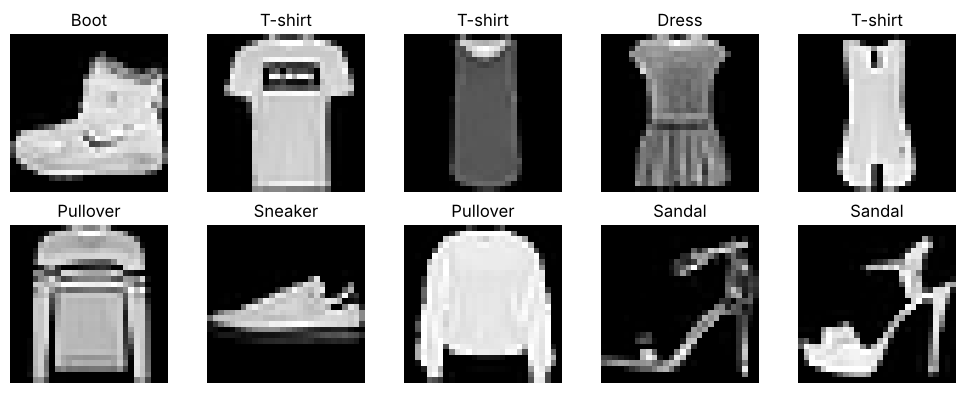

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")
save("fashion_samples")

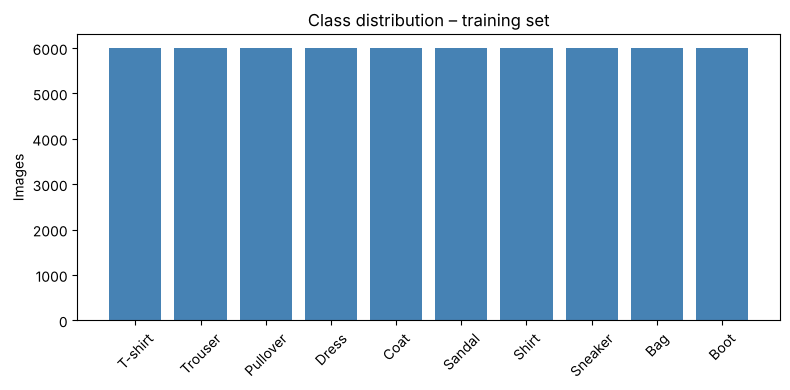

Every class has 6000 training images, so the dataset is balanced.


In [4]:
counts = np.bincount(y_train)
plt.figure(figsize=(8, 4))
plt.bar(class_names, counts, color="steelblue")
plt.title("Class distribution – training set")
plt.ylabel("Images")
plt.xticks(rotation=45)
save("fashion_class_distribution")
print("Every class has", counts.min(), "training images, so the dataset is balanced.")

## 3. Model 1 – Logistic Regression (baseline)

Each image is flattened into 784 pixel values. Logistic Regression has no idea which pixels are next to each other,
so it is a useful baseline for the neural networks.

In [5]:
x_train_flat = x_train.reshape(len(x_train), -1)
x_test_flat = x_test.reshape(len(x_test), -1)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(x_train_flat, y_train)
lr_pred = log_model.predict(x_test_flat)

print("Logistic Regression accuracy:", round(accuracy_score(y_test, lr_pred), 4))

Logistic Regression accuracy: 0.8438


## 4. Model 2 – Artificial Neural Network

Two hidden layers (256 and 128 neurons, ReLU) with 20% dropout to reduce overfitting, and a softmax output for the 10 classes.
Trained for 10 epochs with the Adam optimiser, keeping 20% of the training data for validation.

In [6]:
ann = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.2),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dense(10, activation="softmax"),
])
ann.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
ann.summary()

ann_history = ann.fit(x_train_img, y_train, epochs=10, batch_size=128, validation_split=0.2, verbose=2)
ann_pred = np.argmax(ann.predict(x_test_img, verbose=0), axis=1)
print("ANN accuracy:", round(accuracy_score(y_test, ann_pred), 4))

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (16 outputs left out)

375/375 - 2s - 5ms/step - accuracy: 0.8966 - loss: 0.2763 - val_accuracy: 0.8789 - val_loss: 0.3242


Epoch 10/10


375/375 - 2s - 5ms/step - accuracy: 0.8984 - loss: 0.2682 - val_accuracy: 0.8810 - val_loss: 0.3236


ANN accuracy: 0.8727


## 5. Model 3 – Convolutional Neural Network

Two convolution blocks (32 and 64 filters of 3×3, each followed by 2×2 max pooling) learn local patterns such as edges,
collars and soles. A dense layer of 128 neurons with 30% dropout then does the classification.

In [7]:
cnn = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
cnn.summary()

cnn_history = cnn.fit(x_train_img, y_train, epochs=10, batch_size=128, validation_split=0.2, verbose=2)
cnn_pred = np.argmax(cnn.predict(x_test_img, verbose=0), axis=1)
print("CNN accuracy:", round(accuracy_score(y_test, cnn_pred), 4))

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10


... (16 outputs left out)

375/375 - 10s - 25ms/step - accuracy: 0.9181 - loss: 0.2217 - val_accuracy: 0.9065 - val_loss: 0.2552


Epoch 10/10


375/375 - 9s - 24ms/step - accuracy: 0.9234 - loss: 0.2088 - val_accuracy: 0.9071 - val_loss: 0.2567


CNN accuracy: 0.9036


## 6. Training curves

Training and validation accuracy stay close for both networks, so neither model is badly overfitting.

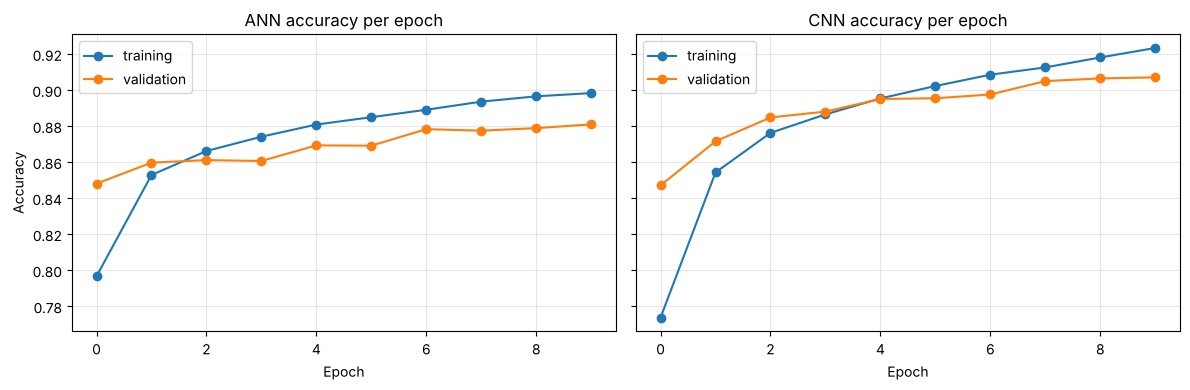

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, hist) in zip(axes, [("ANN", ann_history), ("CNN", cnn_history)]):
    ax.plot(hist.history["accuracy"], marker="o", label="training")
    ax.plot(hist.history["val_accuracy"], marker="o", label="validation")
    ax.set_title(f"{name} accuracy per epoch")
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("Accuracy")
save("fashion_training_curves")

## 7. Evaluation

In [9]:
for name, pred in [("Logistic Regression", lr_pred), ("ANN", ann_pred), ("CNN", cnn_pred)]:
    print(f"===== {name} =====")
    print(classification_report(y_test, pred, target_names=class_names, digits=3))

===== Logistic Regression =====
              precision    recall  f1-score   support

     T-shirt      0.798     0.804     0.801      1000
     Trouser      0.973     0.957     0.965      1000
    Pullover      0.727     0.739     0.733      1000
       Dress      0.827     0.863     0.844      1000
        Coat      0.738     0.759     0.749      1000
      Sandal      0.944     0.922     0.933      1000
       Shirt      0.625     0.569     0.596      1000
     Sneaker      0.912     0.941     0.926      1000
         Bag      0.930     0.935     0.933      1000
        Boot      0.952     0.949     0.950      1000

    accuracy                          0.844     10000
   macro avg      0.843     0.844     0.843     10000
weighted avg      0.843     0.844     0.843     10000

===== ANN =====
              precision    recall  f1-score   support

     T-shirt      0.916     0.713     0.802      1000
     Trouser      0.995     0.960     0.977      1000
    Pullover      0.787     0.

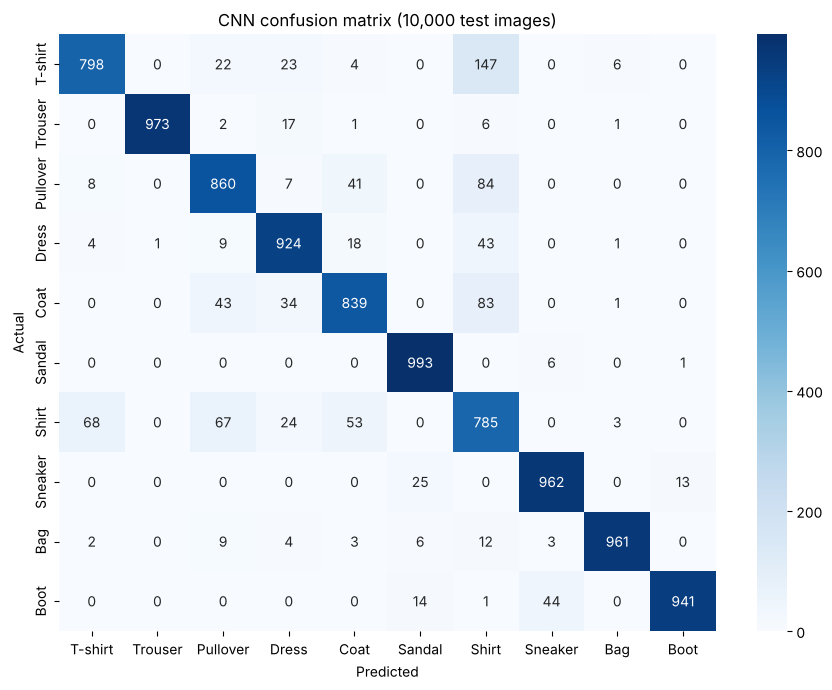

In [10]:
cm = confusion_matrix(y_test, cnn_pred)
plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("CNN confusion matrix (10,000 test images)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
save("fashion_cnn_confusion_matrix")

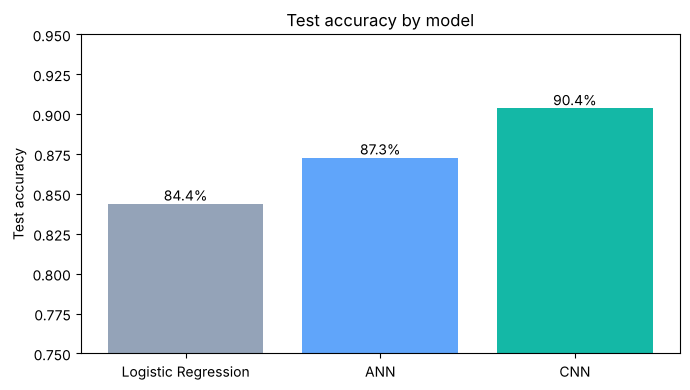

Logistic Regression  84.38%
ANN                  87.27%
CNN                  90.36%


In [11]:
results = {
    "Logistic Regression": accuracy_score(y_test, lr_pred),
    "ANN": accuracy_score(y_test, ann_pred),
    "CNN": accuracy_score(y_test, cnn_pred),
}
plt.figure(figsize=(7, 4))
bars = plt.bar(results.keys(), results.values(), color=["#94a3b8", "#60a5fa", "#14b8a6"])
plt.bar_label(bars, labels=[f"{v:.1%}" for v in results.values()])
plt.ylim(0.75, 0.95)
plt.ylabel("Test accuracy")
plt.title("Test accuracy by model")
save("fashion_accuracy_comparison")

for name, acc in results.items():
    print(f"{name:<20} {acc:.2%}")

## 8. Conclusion

- The **CNN is the most accurate model**, because convolution layers learn local shapes and keep the 2-D structure of the image.
- The ANN beats Logistic Regression thanks to its non-linear hidden layers, but it still sees the image as a flat list of pixels.
- All three models find **Shirt, Pullover, Coat and T-shirt** the hardest classes, because they look alike at 28×28 pixels.
  Trousers, bags, sandals, sneakers and boots are recognised almost perfectly.
- Next steps: data augmentation, batch normalisation, a deeper CNN, and explainability tools such as Grad-CAM to show which pixels drive each prediction.